In [1]:
# open_file()

import pandas as pd
import xlwings as xw
import os

os.chdir("P:\개인자료")
book = xw.Book('Dc-bias_library_V2.xlsx')

In [2]:
df = book.sheets(1).used_range.options(pd.DataFrame).value

In [3]:
df

,None,None,None,None,None,None,None,None,None,None,...,None,None,None,None,None,None,None,None,None,None
None,NaT,NaN,기종,Lot,사이즈,조성,sheet 두께,유전율,DF,DC-Bias 측정,...,None,None,None,None,None,None,None,None,None,None
None,NaT,1.0,05W225MS2,AHBDK14,05,SHBT100(NA392T010),1.1,2828.0,0.061,저주파,...,None,None,None,None,None,None,None,None,None,최종 예측 치
None,NaT,2.0,05W225MS2,AHBDK14,05,SHBT100(NA392T010),1.1,2828.0,0.061,고주파,...,None,None,None,None,None,None,None,None,예측,예측
None,NaT,3.0,05X106MQ5,AH99B1K,05,SHBT100(NA392T010),1.2,3815.160464,0.071,저주파,...,None,None,None,None,None,None,None,Log(1+전계),Log(변화율),변화율 환산
None,NaT,4.0,05X106MQ5,AH99B1K,05,SHBT100(NA392T010),1.2,3815.160464,0.071,고주파,...,a,a',b,c,d,f,None,0.0,2.005723,101.326564
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
임봉섭P,2022-05-31,268.0,03A475MQ5C65,AG3GB6Y,03,SHBT70(NA272PUG1),0.8,4250.862483,0.071927,저주파,...,None,None,None,None,None,None,None,None,None,None
임봉섭P,2022-05-31,269.0,03A225MP3ORN,AG8SB9C,03,SHBT70(NA272PUG1),0.83,3451.966696,0.056869,저주파,...,None,None,None,None,None,None,None,None,None,None
임봉섭P,2022-05-31,270.0,03A225MP3ORN,AG8TB9N,03,SHBT70(NA272PUG1),0.83,3027.544485,0.051773,저주파,...,None,None,None,None,None,None,None,None,None,None
임봉섭P,2022-05-31,271.0,03A225MP3OR2,AG6LB7K,03,SHBT70(NA272PUG1),0.92,3662.634407,0.060282,저주파,...,None,None,None,None,None,None,None,None,None,None


In [4]:
s_df = pd.DataFrame(df.iloc[1:, :21].dropna(axis = 0, how = 'all').values, columns = df.iloc[0, :21].values)

In [5]:
s_df

,NaT,NaN,기종,Lot,사이즈,조성,sheet 두께,유전율,DF,DC-Bias 측정,...,AC(V),전압유지시간,Aging 시간,전계 영역,a,a',b,c,d,f
0,NaT,1.0,05W225MS2,AHBDK14,05,SHBT100(NA392T010),1.1,2828.0,0.061,저주파,...,0.5,60s,24hr,5.727273,-6.663013,6.663013,0.389756,-824364.0,2.018156,0.0
1,NaT,2.0,05W225MS2,AHBDK14,05,SHBT100(NA392T010),1.1,2828.0,0.061,고주파,...,0.01,60s,24hr,5.727273,-7.667761,7.667761,0.463241,-611647.3,2.008805,0.0
2,NaT,3.0,05X106MQ5,AH99B1K,05,SHBT100(NA392T010),1.2,3815.160464,0.071,저주파,...,0.5,60s,24hr,5.25,-11.39497,11.39497,0.27856,-1011754.0,2.007298,0.0
3,NaT,4.0,05X106MQ5,AH99B1K,05,SHBT100(NA392T010),1.2,3815.160464,0.071,고주파,...,0.01,60s,24hr,5.25,-11.42617,11.42617,0.325849,-782284.9,2.008849,0.0
4,NaT,5.0,31B105KCH,AH3EB3C,31,NBT05(NB202P1 70%),15.7,3940.941869,0.011336,저주파,...,1.0,60s,24hr,2.547771,-13.75936,13.75936,0.375514,-335286.4,2.002235,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,2022-05-31,268.0,03A475MQ5C65,AG3GB6Y,03,SHBT70(NA272PUG1),0.8,4250.862483,0.071927,저주파,...,1.0,3s,24hr,7.875,-8.191007,8.191007,0.465081,0.255943,2.008744,0.218004
265,2022-05-31,269.0,03A225MP3ORN,AG8SB9C,03,SHBT70(NA272PUG1),0.83,3451.966696,0.056869,저주파,...,1.0,3s,24hr,7.590361,-8.654993,8.654993,0.432787,-1.270904,2.00487,0.061921
266,2022-05-31,270.0,03A225MP3ORN,AG8TB9N,03,SHBT70(NA272PUG1),0.83,3027.544485,0.051773,저주파,...,1.0,3s,24hr,7.590361,-8.093796,8.093796,0.458168,-0.236801,2.007394,0.12854
267,2022-05-31,271.0,03A225MP3OR2,AG6LB7K,03,SHBT70(NA272PUG1),0.92,3662.634407,0.060282,저주파,...,1.0,3s,24hr,6.847826,-9.09402,9.09402,0.3858,-0.338286,2.006928,0.097851


In [6]:
vol_lev = [x[7] for x in s_df["기종"]]
s_df.insert(len(s_df.columns), 'vol_lev', vol_lev)
s_df.insert(len(s_df.columns), '전압 (Vdc)', 0)

In [7]:
s_df

,NaT,NaN,기종,Lot,사이즈,조성,sheet 두께,유전율,DF,DC-Bias 측정,...,Aging 시간,전계 영역,a,a',b,c,d,f,vol_lev,전압 (Vdc)
0,NaT,1.0,05W225MS2,AHBDK14,05,SHBT100(NA392T010),1.1,2828.0,0.061,저주파,...,24hr,5.727273,-6.663013,6.663013,0.389756,-824364.0,2.018156,0.0,S,0
1,NaT,2.0,05W225MS2,AHBDK14,05,SHBT100(NA392T010),1.1,2828.0,0.061,고주파,...,24hr,5.727273,-7.667761,7.667761,0.463241,-611647.3,2.008805,0.0,S,0
2,NaT,3.0,05X106MQ5,AH99B1K,05,SHBT100(NA392T010),1.2,3815.160464,0.071,저주파,...,24hr,5.25,-11.39497,11.39497,0.27856,-1011754.0,2.007298,0.0,Q,0
3,NaT,4.0,05X106MQ5,AH99B1K,05,SHBT100(NA392T010),1.2,3815.160464,0.071,고주파,...,24hr,5.25,-11.42617,11.42617,0.325849,-782284.9,2.008849,0.0,Q,0
4,NaT,5.0,31B105KCH,AH3EB3C,31,NBT05(NB202P1 70%),15.7,3940.941869,0.011336,저주파,...,24hr,2.547771,-13.75936,13.75936,0.375514,-335286.4,2.002235,0.0,C,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,2022-05-31,268.0,03A475MQ5C65,AG3GB6Y,03,SHBT70(NA272PUG1),0.8,4250.862483,0.071927,저주파,...,24hr,7.875,-8.191007,8.191007,0.465081,0.255943,2.008744,0.218004,Q,0
265,2022-05-31,269.0,03A225MP3ORN,AG8SB9C,03,SHBT70(NA272PUG1),0.83,3451.966696,0.056869,저주파,...,24hr,7.590361,-8.654993,8.654993,0.432787,-1.270904,2.00487,0.061921,P,0
266,2022-05-31,270.0,03A225MP3ORN,AG8TB9N,03,SHBT70(NA272PUG1),0.83,3027.544485,0.051773,저주파,...,24hr,7.590361,-8.093796,8.093796,0.458168,-0.236801,2.007394,0.12854,P,0
267,2022-05-31,271.0,03A225MP3OR2,AG6LB7K,03,SHBT70(NA272PUG1),0.92,3662.634407,0.060282,저주파,...,24hr,6.847826,-9.09402,9.09402,0.3858,-0.338286,2.006928,0.097851,P,0


In [8]:
mat = list(set(s_df["조성"]))
mat = [x for x in mat if pd.isnull(x) == False]
mat

['NBT05(NB202P1 100%)',
 'KBT025(NB242P002)',
 'NBT05(NB202P1 80%)',
 'SHBT160(NB302A010) ',
 'GSBT02(NA272PT112)',
 'SHBT160(A003)',
 'SHBT100(NB202P1)',
 'KBT015(NA272PT112)',
 'KBT015(NB202P1 80%)',
 'SEBT+DRC100100',
 'KBT250+RF002',
 'SHBT100(NA392T010)',
 'KBT025/BCT300(202AH02)',
 'HDBT1.5_70 + DRC',
 'SHBT100(NA372PA01)',
 'SBT030(NA272PT112)',
 'SPMCBT 70nm DRC75% ',
 'SHBT100(NA382P010)',
 'SHBT160(NA272PT112)',
 'SEBT+DRC50100',
 'BT-HP150SP',
 'SHBT50(NA272PUG2)',
 'NBT05(NB202P1 75%)',
 'SHBT100(NA272PT112)',
 'SPBT70-DRC ',
 'SHBT70(NA272PUG1)',
 'KBT015(A210)',
 'NBT05(NB202P1 70%)',
 'SHBT100(NA272P012)',
 'SHBT160+A010',
 'HDBT3-70(NA272PUG1)',
 'SHBT160(NB302A010)',
 'SHBT70+392TDRC',
 'SHBT160(NB322P001) ',
 'KBT015+392T010',
 'KBT015+342AT01',
 'HDBT+DRC100100',
 'NBT05(262C)']

In [9]:
mat.sort()
mat

['BT-HP150SP',
 'GSBT02(NA272PT112)',
 'HDBT+DRC100100',
 'HDBT1.5_70 + DRC',
 'HDBT3-70(NA272PUG1)',
 'KBT015(A210)',
 'KBT015(NA272PT112)',
 'KBT015(NB202P1 80%)',
 'KBT015+342AT01',
 'KBT015+392T010',
 'KBT025(NB242P002)',
 'KBT025/BCT300(202AH02)',
 'KBT250+RF002',
 'NBT05(262C)',
 'NBT05(NB202P1 100%)',
 'NBT05(NB202P1 70%)',
 'NBT05(NB202P1 75%)',
 'NBT05(NB202P1 80%)',
 'SBT030(NA272PT112)',
 'SEBT+DRC100100',
 'SEBT+DRC50100',
 'SHBT100(NA272P012)',
 'SHBT100(NA272PT112)',
 'SHBT100(NA372PA01)',
 'SHBT100(NA382P010)',
 'SHBT100(NA392T010)',
 'SHBT100(NB202P1)',
 'SHBT160(A003)',
 'SHBT160(NA272PT112)',
 'SHBT160(NB302A010)',
 'SHBT160(NB302A010) ',
 'SHBT160(NB322P001) ',
 'SHBT160+A010',
 'SHBT50(NA272PUG2)',
 'SHBT70(NA272PUG1)',
 'SHBT70+392TDRC',
 'SPBT70-DRC ',
 'SPMCBT 70nm DRC75% ']

In [12]:
lib = pd.DataFrame(s_df, columns = ["조성","유전율", "vol_lev", "DC-Bias 측정", '전압 (Vdc)', 'sheet 두께', 'DF', '주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'])

In [13]:
type(lib)

pandas.core.frame.DataFrame

In [14]:
lib

,조성,유전율,vol_lev,DC-Bias 측정,전압 (Vdc),sheet 두께,DF,주파수(kHz),AC(V),전압유지시간,Aging 시간
0,SHBT100(NA392T010),2828.0,S,저주파,0,1.1,0.061,1.0,0.5,60s,24hr
1,SHBT100(NA392T010),2828.0,S,고주파,0,1.1,0.061,100.0,0.01,60s,24hr
2,SHBT100(NA392T010),3815.160464,Q,저주파,0,1.2,0.071,1.0,0.5,60s,24hr
3,SHBT100(NA392T010),3815.160464,Q,고주파,0,1.2,0.071,100.0,0.01,60s,24hr
4,NBT05(NB202P1 70%),3940.941869,C,저주파,0,15.7,0.011336,1.0,1.0,60s,24hr
...,...,...,...,...,...,...,...,...,...,...,...
264,SHBT70(NA272PUG1),4250.862483,Q,저주파,0,0.8,0.071927,1.0,1.0,3s,24hr
265,SHBT70(NA272PUG1),3451.966696,P,저주파,0,0.83,0.056869,1.0,1.0,3s,24hr
266,SHBT70(NA272PUG1),3027.544485,P,저주파,0,0.83,0.051773,1.0,1.0,3s,24hr
267,SHBT70(NA272PUG1),3662.634407,P,저주파,0,0.92,0.060282,1.0,1.0,3s,24hr


In [13]:
# import openpyxl

# # 엑셀 파일 출력
# df.to_excel('P:/개인자료/save_example.xlsx', sheet_name='lib')

In [15]:
lib["유전율"] = [int(x) if x != '사이즈 없음' else x for x in lib['유전율']]

In [16]:
lib

,조성,유전율,vol_lev,DC-Bias 측정,전압 (Vdc),sheet 두께,DF,주파수(kHz),AC(V),전압유지시간,Aging 시간
0,SHBT100(NA392T010),2828,S,저주파,0,1.1,0.061,1.0,0.5,60s,24hr
1,SHBT100(NA392T010),2828,S,고주파,0,1.1,0.061,100.0,0.01,60s,24hr
2,SHBT100(NA392T010),3815,Q,저주파,0,1.2,0.071,1.0,0.5,60s,24hr
3,SHBT100(NA392T010),3815,Q,고주파,0,1.2,0.071,100.0,0.01,60s,24hr
4,NBT05(NB202P1 70%),3940,C,저주파,0,15.7,0.011336,1.0,1.0,60s,24hr
...,...,...,...,...,...,...,...,...,...,...,...
264,SHBT70(NA272PUG1),4250,Q,저주파,0,0.8,0.071927,1.0,1.0,3s,24hr
265,SHBT70(NA272PUG1),3451,P,저주파,0,0.83,0.056869,1.0,1.0,3s,24hr
266,SHBT70(NA272PUG1),3027,P,저주파,0,0.83,0.051773,1.0,1.0,3s,24hr
267,SHBT70(NA272PUG1),3662,P,저주파,0,0.92,0.060282,1.0,1.0,3s,24hr


In [17]:
show = lib.drop(['vol_lev', '전압 (Vdc)', 'DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], axis=1)

In [18]:
show

,조성,유전율,DC-Bias 측정,sheet 두께
0,SHBT100(NA392T010),2828,저주파,1.1
1,SHBT100(NA392T010),2828,고주파,1.1
2,SHBT100(NA392T010),3815,저주파,1.2
3,SHBT100(NA392T010),3815,고주파,1.2
4,NBT05(NB202P1 70%),3940,저주파,15.7
...,...,...,...,...
264,SHBT70(NA272PUG1),4250,저주파,0.8
265,SHBT70(NA272PUG1),3451,저주파,0.83
266,SHBT70(NA272PUG1),3027,저주파,0.83
267,SHBT70(NA272PUG1),3662,저주파,0.92


In [19]:
# filter_fir()

txt = "SHBT70(NA272PUG1)"
filtered = lib[lib["조성"] == txt]

In [20]:
filtered

,조성,유전율,vol_lev,DC-Bias 측정,전압 (Vdc),sheet 두께,DF,주파수(kHz),AC(V),전압유지시간,Aging 시간
34,SHBT70(NA272PUG1),3322,P,저주파,0,0.75,0.057,1.0,0.5,60s,24hr
35,SHBT70(NA272PUG1),3322,P,고주파,0,0.75,0.057,100.0,0.01,60s,24hr
36,SHBT70(NA272PUG1),3334,P,저주파,0,0.75,0.062,1.0,0.5,60s,24hr
37,SHBT70(NA272PUG1),3334,P,고주파,0,0.75,0.062,100.0,0.01,60s,24hr
64,SHBT70(NA272PUG1),0,Q,저주파,0,0.86,0.083,1.0,0.5,60s,24hr
65,SHBT70(NA272PUG1),0,Q,고주파,0,0.86,0.083,100.0,0.01,60s,24hr
219,SHBT70(NA272PUG1),3079,Q,저주파,0,0.7,0.056659,1.0,0.5,60s,24hr
220,SHBT70(NA272PUG1),3079,Q,고주파,0,0.7,0.056659,100.0,0.01,60s,24hr
225,SHBT70(NA272PUG1),2968,P,저주파,0,1.05,0.054322,1.0,1.0,60s,24hr
226,SHBT70(NA272PUG1),2968,P,고주파,0,1.05,0.054322,100.0,0.01,60s,24hr


In [21]:
diel = list(set(filtered["유전율"]))

In [22]:
diel

[0,
 4193,
 2725,
 3334,
 3079,
 4250,
 3662,
 3450,
 3602,
 3027,
 3871,
 2968,
 3322,
 3451,
 4031]

In [23]:
diel = [x for x in diel if pd.isnull(x) == False]

In [24]:
diel

[0,
 4193,
 2725,
 3334,
 3079,
 4250,
 3662,
 3450,
 3602,
 3027,
 3871,
 2968,
 3322,
 3451,
 4031]

In [25]:
diel = [ str(x) for x in diel ]

In [26]:
diel

['0',
 '4193',
 '2725',
 '3334',
 '3079',
 '4250',
 '3662',
 '3450',
 '3602',
 '3027',
 '3871',
 '2968',
 '3322',
 '3451',
 '4031']

In [27]:
diel.sort()

In [28]:
diel

['0',
 '2725',
 '2968',
 '3027',
 '3079',
 '3322',
 '3334',
 '3450',
 '3451',
 '3602',
 '3662',
 '3871',
 '4031',
 '4193',
 '4250']

In [29]:
# filter_sec()
txt = "4031"
filtered_sec = filtered[filtered["유전율"] == int(txt) ]

In [30]:
filtered_sec

,조성,유전율,vol_lev,DC-Bias 측정,전압 (Vdc),sheet 두께,DF,주파수(kHz),AC(V),전압유지시간,Aging 시간
235,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
236,SHBT70(NA272PUG1),4031,Q,고주파,0,0.88,0.079575,100.0,0.01,60s,24hr


In [31]:
# filter_thr()

txt = "저주파"
filtered_thr = filtered_sec[ filtered_sec["DC-Bias 측정"] == txt ]

In [32]:
filtered_thr

,조성,유전율,vol_lev,DC-Bias 측정,전압 (Vdc),sheet 두께,DF,주파수(kHz),AC(V),전압유지시간,Aging 시간
235,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr


In [33]:
idx = filtered_thr.index
idx

Int64Index([235], dtype='int64')

In [34]:
# 선택한 SPL에 해당되는 측정조건 디스플레이
filtered_thr['AC(V)'].iloc[0]

0.5

In [35]:
# 선택한 SPL에 해당되는 측정조건 디스플레이
filtered_thr['주파수(kHz)'].iloc[0]

0.12

In [36]:
# 선택한 SPL에 해당되는 측정조건 디스플레이
filtered_thr['전압유지시간'].iloc[0]

'60s'

In [37]:
# 선택한 SPL에 해당되는 측정조건 디스플레이
filtered_thr['Aging 시간'].iloc[0]

'24hr'

In [57]:
filtered_sec['DF'].iloc[0]

0.079575

In [60]:
filtered_sec["DC-Bias 측정"]

235    저주파
236    고주파
Name: DC-Bias 측정, dtype: object

In [61]:
filtered_thr.reset_index(drop = True, inplace =True)

In [62]:
filtered_thr

,조성,유전율,vol_lev,DC-Bias 측정,전압 (Vdc),sheet 두께,DF,주파수(kHz),AC(V),전압유지시간,Aging 시간
0,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr


In [63]:
filtered_show = filtered_thr.drop(['vol_lev', '전압 (Vdc)', 'DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], axis=1)
filtered_show

,조성,유전율,DC-Bias 측정,sheet 두께
0,SHBT70(NA272PUG1),4031,저주파,0.88


In [64]:
# apply_lib() - self.btnApply.clicked.connect(self.apply_lib)
import numpy as np

In [65]:
p = list(np.arange(0, 10.1, 0.1))

In [66]:
o = list(np.arange(0, 16.1, 0.1))
a = list(np.arange(0, 25.1, 0.1))
l = list(np.arange(0, 35.1, 0.1))
bce = list(np.arange(0, 40.1, 0.1))

In [67]:
p

[0.0,
 0.1,
 0.2,
 0.30000000000000004,
 0.4,
 0.5,
 0.6000000000000001,
 0.7000000000000001,
 0.8,
 0.9,
 1.0,
 1.1,
 1.2000000000000002,
 1.3,
 1.4000000000000001,
 1.5,
 1.6,
 1.7000000000000002,
 1.8,
 1.9000000000000001,
 2.0,
 2.1,
 2.2,
 2.3000000000000003,
 2.4000000000000004,
 2.5,
 2.6,
 2.7,
 2.8000000000000003,
 2.9000000000000004,
 3.0,
 3.1,
 3.2,
 3.3000000000000003,
 3.4000000000000004,
 3.5,
 3.6,
 3.7,
 3.8000000000000003,
 3.9000000000000004,
 4.0,
 4.1000000000000005,
 4.2,
 4.3,
 4.4,
 4.5,
 4.6000000000000005,
 4.7,
 4.800000000000001,
 4.9,
 5.0,
 5.1000000000000005,
 5.2,
 5.300000000000001,
 5.4,
 5.5,
 5.6000000000000005,
 5.7,
 5.800000000000001,
 5.9,
 6.0,
 6.1000000000000005,
 6.2,
 6.300000000000001,
 6.4,
 6.5,
 6.6000000000000005,
 6.7,
 6.800000000000001,
 6.9,
 7.0,
 7.1000000000000005,
 7.2,
 7.300000000000001,
 7.4,
 7.5,
 7.6000000000000005,
 7.7,
 7.800000000000001,
 7.9,
 8.0,
 8.1,
 8.200000000000001,
 8.3,
 8.4,
 8.5,
 8.6,
 8.700000000000001,


In [68]:
len(p)

101

In [69]:
test = pd.DataFrame()

In [70]:
vol_lev = 'Q'

for i in range(len(filtered_thr["vol_lev"])):
    if filtered_thr['vol_lev'][i] == 'S':
        df1 = pd.concat([filtered_thr.iloc[i]]*len(p), axis = 1)
        test = pd.concat([test, df1], axis = 1)
    elif filtered_thr['vol_lev'][i] == 'R':
        df2 = pd.concat([filtered_thr.iloc[i]]*len(p), axis = 1)
        test = pd.concat([test, df2], axis = 1)
    elif filtered_thr['vol_lev'][i] == 'Q':
        df3 = pd.concat([filtered_thr.iloc[i]]*len(p), axis = 1)
        test = pd.concat([test, df3], axis = 1)
    elif filtered_thr['vol_lev'][i] == 'P':
        df4 = pd.concat([filtered_thr.iloc[i]]*len(p), axis = 1)
        test = pd.concat([test, df4], axis = 1)
    elif filtered_thr['vol_lev'][i] == 'O':
        df5 = pd.concat([filtered_thr.iloc[i]]*len(o), axis = 1)
        test = pd.concat([test, df5], axis = 1)
    elif filtered_thr['vol_lev'][i] == 'A':
        df6 = pd.concat([filtered_thr.iloc[i]] * len(a), axis=1)
        test = pd.concat([test, df6], axis=1)
    elif filtered_thr['vol_lev'][i] == 'L':
        df7 = pd.concat([filtered_thr.iloc[i]] * len(l), axis=1)
        test = pd.concat([test, df7], axis=1)
    elif filtered_thr['vol_lev'][i] == 'B' or 'C' or 'E':
        df8 = pd.concat([filtered_thr.iloc[i]] * len(bce), axis=1)
        test = pd.concat([test, df8], axis=1)



101

In [71]:
df3

,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
조성,SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),...,SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1),SHBT70(NA272PUG1)
유전율,4031,4031,4031,4031,4031,4031,4031,4031,4031,4031,...,4031,4031,4031,4031,4031,4031,4031,4031,4031,4031
vol_lev,Q,Q,Q,Q,Q,Q,Q,Q,Q,Q,...,Q,Q,Q,Q,Q,Q,Q,Q,Q,Q
DC-Bias 측정,저주파,저주파,저주파,저주파,저주파,저주파,저주파,저주파,저주파,저주파,...,저주파,저주파,저주파,저주파,저주파,저주파,저주파,저주파,저주파,저주파
전압 (Vdc),0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
sheet 두께,0.88,0.88,0.88,0.88,0.88,0.88,0.88,0.88,0.88,0.88,...,0.88,0.88,0.88,0.88,0.88,0.88,0.88,0.88,0.88,0.88
DF,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,...,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575,0.079575
주파수(kHz),0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.12,...,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.12,0.12
AC(V),0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,...,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5
전압유지시간,60s,60s,60s,60s,60s,60s,60s,60s,60s,60s,...,60s,60s,60s,60s,60s,60s,60s,60s,60s,60s


In [81]:
fin = test.T.reset_index(drop = True)

In [82]:
fin

,조성,유전율,vol_lev,DC-Bias 측정,전압 (Vdc),sheet 두께,DF,주파수(kHz),AC(V),전압유지시간,Aging 시간
0,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
1,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
2,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
3,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
4,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
...,...,...,...,...,...,...,...,...,...,...,...
96,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
97,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
98,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr
99,SHBT70(NA272PUG1),4031,Q,저주파,0,0.88,0.079575,0.12,0.5,60s,24hr


In [83]:
len(fin["vol_lev"])

101

In [84]:
for i in range(len(fin["vol_lev"])):

    if fin['vol_lev'][i] == 'S' and fin['전압 (Vdc)'][i] == 0:
        for j in range(len(p)):
            fin['전압 (Vdc)'][i + j] = p[j]
    elif fin['vol_lev'][i] == 'R' and fin['전압 (Vdc)'][i] == 0:
        for j in range(len(p)):
            fin['전압 (Vdc)'][i + j] = p[j]
    elif fin['vol_lev'][i] == 'Q' and fin['전압 (Vdc)'][i] == 0:
        for j in range(len(p)):
            fin['전압 (Vdc)'][i + j] = p[j]
    elif fin['vol_lev'][i] == 'P' and fin['전압 (Vdc)'][i] == 0:
        for j in range(len(p)):
            fin['전압 (Vdc)'][i + j] = p[j]
    elif fin['vol_lev'][i] == 'O' and fin['전압 (Vdc)'][i] == 0:
        for j in range(len(o)):
            fin['전압 (Vdc)'][i + j] = o[j]
    elif fin['vol_lev'][i] == 'A' and fin['전압 (Vdc)'][i] == 0:
        for j in range(len(a)):
            fin['전압 (Vdc)'][i + j] = a[j]
    elif fin['vol_lev'][i] == 'L' and fin['전압 (Vdc)'][i] == 0:
        for j in range(len(l)):
            fin['전압 (Vdc)'][i + j] = l[j]
    elif (fin['vol_lev'][i] == 'B'or 'C'or'E') and fin['전압 (Vdc)'][i] == 0:
        for j in range(len(bce)):
            fin['전압 (Vdc)'][i + j] = bce[j]

In [85]:
fin

,조성,유전율,vol_lev,DC-Bias 측정,전압 (Vdc),sheet 두께,DF,주파수(kHz),AC(V),전압유지시간,Aging 시간
0,SHBT70(NA272PUG1),4031,Q,저주파,0.0,0.88,0.079575,0.12,0.5,60s,24hr
1,SHBT70(NA272PUG1),4031,Q,저주파,0.1,0.88,0.079575,0.12,0.5,60s,24hr
2,SHBT70(NA272PUG1),4031,Q,저주파,0.2,0.88,0.079575,0.12,0.5,60s,24hr
3,SHBT70(NA272PUG1),4031,Q,저주파,0.3,0.88,0.079575,0.12,0.5,60s,24hr
4,SHBT70(NA272PUG1),4031,Q,저주파,0.4,0.88,0.079575,0.12,0.5,60s,24hr
...,...,...,...,...,...,...,...,...,...,...,...
96,SHBT70(NA272PUG1),4031,Q,저주파,9.6,0.88,0.079575,0.12,0.5,60s,24hr
97,SHBT70(NA272PUG1),4031,Q,저주파,9.7,0.88,0.079575,0.12,0.5,60s,24hr
98,SHBT70(NA272PUG1),4031,Q,저주파,9.8,0.88,0.079575,0.12,0.5,60s,24hr
99,SHBT70(NA272PUG1),4031,Q,저주파,9.9,0.88,0.079575,0.12,0.5,60s,24hr


In [86]:
# sheet 두께 입력 받은 후 전계 칼럼 추가
st = input('Sheet T = ?') 
ef = fin['전압 (Vdc)']/float(st)

for i in range(len(ef)):
    ef[i] = np.round(ef[i], 2)

fin.insert(len(fin.columns), '전계 (V/um)', ef)

fin.drop(columns = ['vol_lev', 'DC-Bias 측정','DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], inplace = True)

fin

,조성,유전율,전압 (Vdc),sheet 두께,전계 (V/um)
0,SHBT70(NA272PUG1),4031,0.0,0.88,0.0
1,SHBT70(NA272PUG1),4031,0.1,0.88,0.11
2,SHBT70(NA272PUG1),4031,0.2,0.88,0.23
3,SHBT70(NA272PUG1),4031,0.3,0.88,0.34
4,SHBT70(NA272PUG1),4031,0.4,0.88,0.45
...,...,...,...,...,...
96,SHBT70(NA272PUG1),4031,9.6,0.88,10.91
97,SHBT70(NA272PUG1),4031,9.7,0.88,11.02
98,SHBT70(NA272PUG1),4031,9.8,0.88,11.14
99,SHBT70(NA272PUG1),4031,9.9,0.88,11.25


In [87]:
s_df.iloc[idx]

,NaT,NaN,기종,Lot,사이즈,조성,sheet 두께,유전율,DF,DC-Bias 측정,...,Aging 시간,전계 영역,a,a',b,c,d,f,vol_lev,전압 (Vdc)
235,2022-05-25,239.0,05A156MQ5N64,AG9CB18,05,SHBT70(NA272PUG1),0.88,4031.0,0.079575,저주파,...,24hr,7.159091,-5.902346,5.902346,0.539383,0.518615,2.027302,0.447222,Q,0


In [88]:

# , columns = ['a', 'b', 'c', 'd', 'f']
cst = pd.DataFrame(s_df.iloc[idx], columns = ['a', 'b', 'c', 'd', 'f'])
cst.columns = ['a (증가율)', 'b (변곡점)', 'c (점근선 1)', 'd (점근선 2)', 'f (검정력)']
# make_tableConst(self.cst)

const = [float(x) for x in cst.iloc[0].values]
const

[-5.902346, 0.5393833, 0.5186153, 2.0273025, 0.447222]

In [89]:
cap_pct = []
for i in range(len(fin['전계 (V/um)'])):
    cap_pct.append( 10 ** (const[2] + (const[3] - const[2])/(1 + np.exp(-const[0] * (np.log( 1 + fin['전계 (V/um)'][i]) - const[1]))) ** const[4]) )
print(cap_pct)

fin.insert(len(fin.columns), '용량변화율 %', cap_pct)
fin

[100.03601002638135, 95.11437551522934, 87.31619890741754, 78.04377499726313, 67.38744232181087, 55.38862583287851, 45.15567487853171, 35.64325520543449, 28.669336332432714, 23.24956366278531, 18.798530421215432, 15.750955411407924, 13.437342738734973, 11.526612288270574, 10.18556949696807, 9.132461442454069, 8.227135159402797, 7.564654484273385, 6.979581973618814, 6.540411885301286, 6.173674324941348, 5.838852227209786, 5.579709331766677, 5.357449272233999, 5.149302959704937, 4.984399706243149, 4.840058990978657, 4.702231364460218, 4.591066614536672, 4.483787230995031, 4.396408497803085, 4.318040716866401, 4.2414335969881325, 4.1782865142123775, 4.1210469895197335, 4.064512606745761, 4.017458541323209, 3.974436273462666, 3.9315829572155647, 3.895630361138602, 3.859642908877934, 3.829310147305964, 3.8012597284924508, 3.773004858029323, 3.749046883768645, 3.7267712081874733, 3.7042121727994646, 3.684985468475612, 3.667025171761876, 3.64875158800942, 3.633107797159489, 3.617146357564015,

,조성,유전율,전압 (Vdc),sheet 두께,전계 (V/um),용량변화율 %
0,SHBT70(NA272PUG1),4031,0.0,0.88,0.0,100.036010
1,SHBT70(NA272PUG1),4031,0.1,0.88,0.11,95.114376
2,SHBT70(NA272PUG1),4031,0.2,0.88,0.23,87.316199
3,SHBT70(NA272PUG1),4031,0.3,0.88,0.34,78.043775
4,SHBT70(NA272PUG1),4031,0.4,0.88,0.45,67.387442
...,...,...,...,...,...,...
96,SHBT70(NA272PUG1),4031,9.6,0.88,10.91,3.370315
97,SHBT70(NA272PUG1),4031,9.7,0.88,11.02,3.368631
98,SHBT70(NA272PUG1),4031,9.8,0.88,11.14,3.366857
99,SHBT70(NA272PUG1),4031,9.9,0.88,11.25,3.365287


In [90]:
x = [float(a) for a in fin['전압 (Vdc)'].values]
y = fin['용량변화율 %'].values
print(x, y)


[0.0, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9, 1.0, 1.1, 1.2000000000000002, 1.3, 1.4000000000000001, 1.5, 1.6, 1.7000000000000002, 1.8, 1.9000000000000001, 2.0, 2.1, 2.2, 2.3000000000000003, 2.4000000000000004, 2.5, 2.6, 2.7, 2.8000000000000003, 2.9000000000000004, 3.0, 3.1, 3.2, 3.3000000000000003, 3.4000000000000004, 3.5, 3.6, 3.7, 3.8000000000000003, 3.9000000000000004, 4.0, 4.1000000000000005, 4.2, 4.3, 4.4, 4.5, 4.6000000000000005, 4.7, 4.800000000000001, 4.9, 5.0, 5.1000000000000005, 5.2, 5.300000000000001, 5.4, 5.5, 5.6000000000000005, 5.7, 5.800000000000001, 5.9, 6.0, 6.1000000000000005, 6.2, 6.300000000000001, 6.4, 6.5, 6.6000000000000005, 6.7, 6.800000000000001, 6.9, 7.0, 7.1000000000000005, 7.2, 7.300000000000001, 7.4, 7.5, 7.6000000000000005, 7.7, 7.800000000000001, 7.9, 8.0, 8.1, 8.200000000000001, 8.3, 8.4, 8.5, 8.6, 8.700000000000001, 8.8, 8.9, 9.0, 9.1, 9.200000000000001, 9.3, 9.4, 9.5, 9.600000000000001, 9.700000000000

In [101]:
print(type(x), x)

<class 'list'> [0.0, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9, 1.0, 1.1, 1.2000000000000002, 1.3, 1.4000000000000001, 1.5, 1.6, 1.7000000000000002, 1.8, 1.9000000000000001, 2.0, 2.1, 2.2, 2.3000000000000003, 2.4000000000000004, 2.5, 2.6, 2.7, 2.8000000000000003, 2.9000000000000004, 3.0, 3.1, 3.2, 3.3000000000000003, 3.4000000000000004, 3.5, 3.6, 3.7, 3.8000000000000003, 3.9000000000000004, 4.0, 4.1000000000000005, 4.2, 4.3, 4.4, 4.5, 4.6000000000000005, 4.7, 4.800000000000001, 4.9, 5.0, 5.1000000000000005, 5.2, 5.300000000000001, 5.4, 5.5, 5.6000000000000005, 5.7, 5.800000000000001, 5.9, 6.0, 6.1000000000000005, 6.2, 6.300000000000001, 6.4, 6.5, 6.6000000000000005, 6.7, 6.800000000000001, 6.9, 7.0, 7.1000000000000005, 7.2, 7.300000000000001, 7.4, 7.5, 7.6000000000000005, 7.7, 7.800000000000001, 7.9, 8.0, 8.1, 8.200000000000001, 8.3, 8.4, 8.5, 8.6, 8.700000000000001, 8.8, 8.9, 9.0, 9.1, 9.200000000000001, 9.3, 9.4, 9.5, 9.600000000000001,

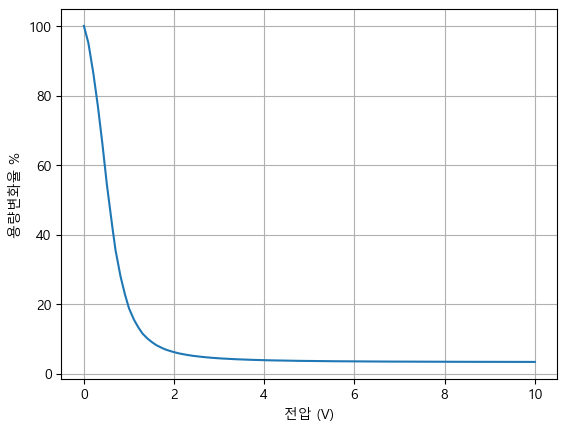

In [91]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
# from scipy.interpolate import make_interp_spline
from scipy import interpolate

font_name = mpl.font_manager.FontProperties(fname='C:/Windows/Fonts/malgun.ttf').get_name()
mpl.rc('font', family=font_name)
mpl.rc('axes', unicode_minus = False)

xs = np.linspace(x[0], x[-1], 1000)
f = interpolate.interp1d(x, y, kind = 'linear')
ys = f(xs)

plt.plot(xs, ys)
plt.xlabel('전압 (V)')
plt.ylabel('용량변화율 %')

plt.grid(True)


plt.show()

In [93]:
const = [[-5.902346, 0.5393833, 0.5186153, 2.0273025, 0.447222]]
cst = pd.DataFrame(data=const, columns = ['a (증가율)', 'b (변곡점)', 'c (점근선 1)', 'd (점근선 2)', 'f (검정력)'])
# cst.columms = ['a (증가율)', 'b (변곡점)', 'c (점근선 1)', 'd (점근선 2)', 'f (검정력)']

cst

,a (증가율),b (변곡점),c (점근선 1),d (점근선 2),f (검정력)
0,-5.902346,0.539383,0.518615,2.027302,0.447222


filtered_thr                     조성   유전율 vol_lev DC-Bias 측정  전압 (Vdc) sheet 두께        DF  \
235  SHBT70(NA272PUG1)  4031       Q        저주파         0     0.88  0.079575   

    주파수(kHz) AC(V) 전압유지시간 Aging 시간  
235     0.12   0.5    60s     24hr   Int64Index([235], dtype='int64')
fin                     조성   유전율 vol_lev DC-Bias 측정 전압 (Vdc) sheet 두께        DF  \
0    SHBT70(NA272PUG1)  4031       Q        저주파      0.0     0.88  0.079575   
1    SHBT70(NA272PUG1)  4031       Q        저주파      0.1     0.88  0.079575   
2    SHBT70(NA272PUG1)  4031       Q        저주파      0.2     0.88  0.079575   
3    SHBT70(NA272PUG1)  4031       Q        저주파      0.3     0.88  0.079575   
4    SHBT70(NA272PUG1)  4031       Q        저주파      0.4     0.88  0.079575   
..                 ...   ...     ...        ...      ...      ...       ...   
96   SHBT70(NA272PUG1)  4031       Q        저주파      9.6     0.88  0.079575   
97   SHBT70(NA272PUG1)  4031       Q        저주파      9.7     0.88  0.079575   
98  

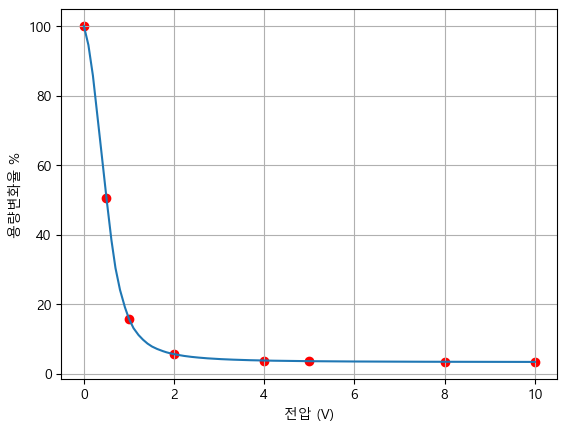

저장완료 성공적으로 저장되었습니다.


C:\Users\Administrator\AppData\Local\Temp\ipykernel_26784\3268581299.py:138: FutureWarning: save is not part of the public API, usage can give unexpected results and will be removed in a future version
  writer.save()


In [98]:
import pandas as pd
import xlwings as xw
import os

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
# from scipy.interpolate import make_interp_spline
from scipy import interpolate

# def open_file(self):
os.chdir("P:\개인자료")
book = xw.Book('Dc-bias_library_V2.xlsx')

df = book.sheets(1).used_range.options(pd.DataFrame).value
s_df = pd.DataFrame(df.iloc[1:, :21].dropna(axis = 0, how = 'all').values, columns = df.iloc[0, :21].values)

vol_lev = [x[7] for x in s_df["기종"]]
s_df.insert(len(s_df.columns), 'vol_lev', vol_lev)
s_df.insert(len(s_df.columns), '전압 (Vdc)', 0)

lib = pd.DataFrame(s_df, columns = ["조성","유전율", "vol_lev", "DC-Bias 측정", '전압 (Vdc)', 'sheet 두께', 'DF', '주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'])
lib["유전율"] = [int(x) if x != '사이즈 없음' else x for x in lib['유전율']]

show = lib.drop(['vol_lev', '전압 (Vdc)', 'DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], axis=1)

# def filter():
txt = "SHBT70(NA272PUG1)"
filtered = lib[lib["조성"] == txt]

diel = list(set(filtered["유전율"]))
diel = [x for x in diel if pd.isnull(x) == False]
diel = [ str(x) for x in diel ]

txt = "4031"
filtered_sec = filtered[filtered["유전율"] == int(txt) ]

txt = "저주파"
filtered_thr = filtered_sec[ filtered_sec["DC-Bias 측정"] == txt ]
idx = filtered_thr.index
print('filtered_thr', filtered_thr, idx)

filtered_thr.reset_index(drop = True, inplace =True)
filtered_show = filtered_thr.drop(['vol_lev', '전압 (Vdc)', 'DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], axis=1)

# def apply_lib(self):
p = list(np.arange(0, 10.1, 0.1))
test = pd.DataFrame()

vol_lev = 'Q'
for i in range(len(filtered_thr["vol_lev"])):
    df3 = pd.concat([filtered_thr.iloc[i]]*len(p), axis = 1)
    test = pd.concat([test, df3], axis = 1)

fin = test.T.reset_index(drop = True)

for i in range(len(fin["vol_lev"])):
    if fin['전압 (Vdc)'][i] == 0:
        for j in range(len(p)):
            fin['전압 (Vdc)'][i + j] = p[j]

print('fin',fin)

# sheet 두께 입력 받은 후 전계 칼럼 추가
# st = input('Sheet T = ?') 
st = 0.8
ef = fin['전압 (Vdc)']/float(st)

for i in range(len(ef)):
    ef[i] = np.round(ef[i], 2)

fin.insert(len(fin.columns), '전계 (V/um)', ef)

fin.drop(columns = ['vol_lev', 'DC-Bias 측정','DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], inplace = True)

print('fin', fin)

const = [[-5.902346, 0.5393833, 0.5186153, 2.0273025, 0.447222]]
cst = pd.DataFrame(data=const, columns = ['a', 'b', 'c', 'd', 'f'])
# cst.columms = ["a (증가율)", "b (변곡점)", "c (점근선 1)", "d (점근선 2)", "f (검정력)"]

const = [float(x) for x in cst.iloc[0].values]

cap_pct = []
for i in range(len(fin['전계 (V/um)'])):
    cap_pct.append( 10 ** (const[2] + (const[3] - const[2])/(1 + np.exp(-const[0] * (np.log( 1 + fin['전계 (V/um)'][i]) - const[1]))) ** const[4]) )
print(cap_pct)

fin.insert(len(fin.columns), '용량변화율 %', cap_pct)
print('fin', fin)

p_show = [0, 0.5, 1, 2, 3.15, 4, 5, 6.3, 8, 10]
cap = 1

low = fin.copy()
low_cap = float(cap) * fin['용량변화율 %'] * 0.01
low.insert(len(low.columns), '저주파 유효 용량', low_cap)
low.drop(['sheet 두께'], axis=1, inplace=True)
low_show = low.copy()
low_show['용량변화율 %'] = np.round(low_show['용량변화율 %'], 2)
low_show['저주파 유효 용량'] = np.round(low_show['저주파 유효 용량'], 2)

# 보이는 테이블 전압 필터링
low_show = low_show[low_show['전압 (Vdc)'].isin(p_show)]
print('low_show', low_show)
print('cst', cst)

    # self.make_tableLib(self.low_show)
# self.make_tableConst(self.cst)

# def draw_graph(self):
x = [float(a) for a in fin['전압 (Vdc)'].values]
y = fin['용량변화율 %'].values

xs = np.linspace(x[0], x[-1], 1000)
f = interpolate.interp1d(x, y, kind = 'linear')

ys = f(xs)

xp = [float(a) for a in low_show['전압 (Vdc)'].values]
yp = low_show['용량변화율 %'].values

plt.scatter(xp,yp, color = 'red')
plt.plot(xs, ys)

plt.xlabel('전압 (V)')
plt.ylabel('용량변화율 %')

plt.grid(True)
plt.show()

# def make_excel(self):
new_file = 'DC-bias library 분석'
newfile = 'P:.\\..\\{}.xlsx'.format(new_file)
# newfile = './{}.xlsx'.format(new_file)
writer = pd.ExcelWriter(newfile)
low.to_excel(writer, index=False, engine = 'openpyxl')
writer.save()
print('저장완료', '성공적으로 저장되었습니다.')



In [1]:
from PyQt5.QtWidgets import *
from PyQt5.QtCore import *
import pandas as pd

import sys, os
import xlwings as xw

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.interpolate import make_interp_spline
from scipy import interpolate

font_name = mpl.font_manager.FontProperties(fname='C:/Windows/Fonts/malgun.ttf').get_name()
mpl.rc('font', family=font_name)
mpl.rc('axes', unicode_minus = False)

from main_wnd import Ui_MainWindow
from mypandasModel import *

class Form(QMainWindow, Ui_MainWindow):
    def __init__(self):
        super().__init__()
        self.setupUi(self)

        self.open_filter()
        self.apply_lib()

        self.btnGraph.clicked.connect(self.draw_graph)
        self.btnExcel.clicked.connect(self.make_excel)
                
        self.df = pd.DataFrame()
        self.lib = pd.DataFrame()
        self.test = pd.DataFrame()
     

    def make_tableLib(self, df):
        model = pandasModel(df)
        self.tableLib.setModel(model)
        self.tableLib.resizeColumnsToContents()
        self.tableLib.horizontalHeader().setSectionResizeMode(QHeaderView.Stretch)
        self.tableLib.verticalHeader().setSectionResizeMode(QHeaderView.Stretch)       

    def make_tableConst(self, df):
        self.tableConst.setHidden(False)
        model = pandasModel(df)
        self.tableConst.setModel(model)
        self.tableConst.resizeColumnsToContents()
        self.tableConst.horizontalHeader().setSectionResizeMode(QHeaderView.Stretch)
        self.tableConst.verticalHeader().setSectionResizeMode(QHeaderView.Stretch) 

    def open_filter(self):
        os.chdir("P:\개인자료")
        book = xw.Book('Dc-bias_library_V2.xlsx')

        df = book.sheets(1).used_range.options(pd.DataFrame).value
        self.df = pd.DataFrame(df.iloc[1:, :21].dropna(axis = 0, how = 'all').values, columns = df.iloc[0, :21].values)

        vol_lev = [x[7] for x in self.df["기종"]]
        self.df.insert(len(self.df.columns), 'vol_lev', vol_lev)
        self.df.insert(len(self.df.columns), '전압 (Vdc)', 0)

        self.lib = pd.DataFrame(self.df, columns = ["조성","유전율", "vol_lev", "DC-Bias 측정", '전압 (Vdc)', 'sheet 두께', 'DF', '주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'])
        self.lib["유전율"] = [int(x) if x != '사이즈 없음' else x for x in self.lib['유전율']]

        show = self.lib.drop(['vol_lev', '전압 (Vdc)', 'DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], axis=1)

        txt = "SHBT70(NA272PUG1)"
        filtered = self.lib[self.lib["조성"] == txt]

        diel = list(set(filtered["유전율"]))
        diel = [x for x in diel if pd.isnull(x) == False]
        diel = [ str(x) for x in diel ]

        txt = "4031"
        filtered_sec = filtered[filtered["유전율"] == int(txt) ]

        txt = "저주파"
        self.filtered_thr = filtered_sec[ filtered_sec["DC-Bias 측정"] == txt ]
        self.idx = self.filtered_thr.index
        print(self.filtered_thr, self.idx)

        self.filtered_thr.reset_index(drop = True, inplace =True)
        filtered_show = self.filtered_thr.drop(['vol_lev', '전압 (Vdc)', 'DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], axis=1)
        self.make_tableLib(filtered_show)
        self.CaplineEdit.clear()

    def apply_lib(self):
        p = list(np.arange(0, 10.1, 0.1))
        self.test = pd.DataFrame()

        vol_lev = 'Q'
        for i in range(len(self.filtered_thr["vol_lev"])):
            df3 = pd.concat([self.filtered_thr.iloc[i]]*len(p), axis = 1)
            self.test = pd.concat([self.test, df3], axis = 1)

        self.fin = self.test.T.reset_index(drop = True)

        for i in range(len(self.fin["vol_lev"])):
            if self.fin['전압 (Vdc)'][i] == 0:
                for j in range(len(p)):
                    self.fin['전압 (Vdc)'][i + j] = p[j]

        # sheet 두께 입력 받은 후 전계 칼럼 추가
        # self.st = self.STlineEdit.text()
        # st = input('Sheet T = ?') 
        st = 0.8 
        ef = self.fin['전압 (Vdc)']/st

        for i in range(len(ef)):
            ef[i] = np.round(ef[i], 2)

        self.fin.insert(len(self.fin.columns), '전계 (V/um)', ef)

        self.fin.drop(columns = ['vol_lev', 'DC-Bias 측정','DF','주파수(kHz)', 'AC(V)', '전압유지시간', 'Aging 시간'], inplace = True)
        print(self.fin)
        
        # const = [[-5.902346, 0.5393833, 0.5186153, 2.0273025, 0.447222]]
        self.cst = pd.DataFrame(self.df.iloc[self.idx], columns = ['a', 'b', 'c', 'd', 'f'])
        self.cst.columms = ["a (증가율)", "b (변곡점)", "c (점근선 1)", "d (점근선 2)", "f (검정력)"]

        self.const = [float(x) for x in self.cst.iloc[0].values]

        cap_pct = []
        for i in range(len(self.fin['전계 (V/um)'])):
            cap_pct.append( 10 ** (self.const[2] + (self.const[3] - self.const[2])/(1 + np.exp(-self.const[0] * (np.log( 1 + self.fin['전계 (V/um)'][i]) - self.const[1]))) ** self.const[4]) )
          
        self.fin.insert(len(self.fin.columns), '용량변화율 %', cap_pct)

        p_show = [0, 0.5, 1, 2, 3.15, 4, 5, 6.3, 8, 10]
        # cap = self.CaplineEdit.text()
        # cap = input('cap = ?') 
        cap = 1
             
        self.low = self.fin.copy()
        low_cap = float(cap) * self.fin['용량변화율 %'] * 0.01
        self.low.insert(len(self.low.columns), '저주파 유효 용량', low_cap)
        self.low.drop(['sheet 두께'], axis=1, inplace=True)

        self.low_show = self.low.copy()
        self.low_show['용량변화율 %'] = np.round(self.low_show['용량변화율 %'], 2)
        self.low_show['저주파 유효 용량'] = np.round(self.low_show['저주파 유효 용량'], 2)

        # 보이는 테이블 전압 필터링
        self.low_show = self.low_show[self.low_show['전압 (Vdc)'].isin(p_show)]
        self.make_tableLib(self.low_show)
        self.make_tableConst(self.cst)
       
    def draw_graph(self):
        x = [float(a) for a in self.fin['전압 (Vdc)'].values]
        y = self.fin['용량변화율 %'].values

        xs = np.linspace(x[0], x[-1], 1000)
        f = interpolate.interp1d(x, y, kind = 'linear')

        ys = f(xs)
        
        xp = [float(a) for a in self.low_show['전압 (Vdc)'].values]
        yp = self.low_show['용량변화율 %'].values
        
        plt.scatter(xp,yp, color = 'red')
        plt.plot(xs, ys)

        plt.xlabel('전압 (V)')
        plt.ylabel('용량변화율 %')

        plt.grid(True)
        plt.show()

    def make_excel(self):
        new_file = 'DC-bias library 분석'
        
        newfile = 'P:.\\..\\{}.xlsx'.format(new_file)
        # newfile = './{}.xlsx'.format(new_file)
        writer = pd.ExcelWriter(newfile)
        self.low.to_excel(writer, index=False, engine = 'openpyxl')
        writer.save()
        QMessageBox.information(self, '저장완료', '성공적으로 저장되었습니다.')
  
if __name__ == '__main__':
    app = QApplication(sys.argv)
    w = Form()
    w.show()
    app.exec_()

                    조성   유전율 vol_lev DC-Bias 측정  전압 (Vdc) sheet 두께        DF  \
235  SHBT70(NA272PUG1)  4031       Q        저주파         0     0.88  0.079575   

    주파수(kHz) AC(V) 전압유지시간 Aging 시간  
235     0.12   0.5    60s     24hr   Int64Index([235], dtype='int64')
                    조성   유전율 전압 (Vdc) sheet 두께 전계 (V/um)
0    SHBT70(NA272PUG1)  4031      0.0     0.88       0.0
1    SHBT70(NA272PUG1)  4031      0.1     0.88      0.12
2    SHBT70(NA272PUG1)  4031      0.2     0.88      0.25
3    SHBT70(NA272PUG1)  4031      0.3     0.88      0.38
4    SHBT70(NA272PUG1)  4031      0.4     0.88       0.5
..                 ...   ...      ...      ...       ...
96   SHBT70(NA272PUG1)  4031      9.6     0.88      12.0
97   SHBT70(NA272PUG1)  4031      9.7     0.88     12.12
98   SHBT70(NA272PUG1)  4031      9.8     0.88     12.25
99   SHBT70(NA272PUG1)  4031      9.9     0.88     12.38
100  SHBT70(NA272PUG1)  4031     10.0     0.88      12.5

[101 rows x 5 columns]


C:\Users\Administrator\AppData\Local\Temp\ipykernel_20716\1677528862.py:120: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  self.cst.columms = ["a (증가율)", "b (변곡점)", "c (점근선 1)", "d (점근선 2)", "f (검정력)"]


<class 'numpy.ndarray'> [ 0.          1.65346982  3.30693964  4.96040945  6.61387927  8.26734909
  9.92081891 11.57428872 13.22775854 14.88122836 16.53469818 18.18816799
 19.84163781 21.49510763 23.14857745 24.80204727 26.45551708 28.1089869
 29.76245672 31.41592654] [ 1.         -0.08257935 -0.9863613   0.24548549  0.94581724 -0.40169542
 -0.87947375  0.54694816  0.78914051 -0.67728157 -0.67728157  0.78914051
  0.54694816 -0.87947375 -0.40169542  0.94581724  0.24548549 -0.9863613
 -0.08257935  1.        ]


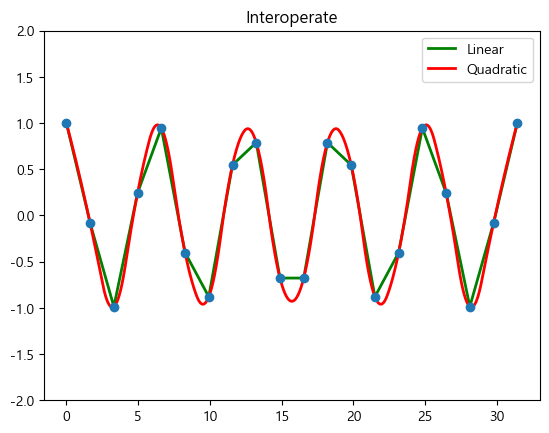

In [97]:
import numpy as np
from scipy.interpolate import interp1d
from matplotlib import pyplot as plt

# Cosine 함수를 0부터 10pi까지 20개 만든다.
x = np.linspace(0,10*np.pi, 20)
y = np.cos(x)
print(type(x), x, y)

#interoperate 함수로 보간법을 적용하여 linear(선형보정) quadratic(부드러운 보정) 두가지 방법으로 만든다
fl = interp1d(x,y,kind = 'linear')
fq = interp1d(x,y,kind = 'quadratic')

xint = np.linspace(x.min(), x.max(), 1000)
yintl = fl(xint)
yintq = fq(xint)

# Plot the data and the interpolation
plt.plot(xint, yintl, color = 'green', linewidth=2)
plt.plot(xint, yintq, color = 'red', linewidth=2)
plt.legend(['Linear','Quadratic'])
plt.plot(x,y,'o')    #값의 위치를 점으로 표현
plt.ylim(-2,2)

plt.title('Interoperate')
plt.show()

In [6]:
new_file='aaa'
print('P:.\\..\\{}.xlsx'.format(new_file))

# self.filtered_thr['DC-Bias 측정'][0] == '저주파': self.low = self.fin.copy()
# self.filtered_thr['DC-Bias 측정'][0] == '고주파': self.high self.fin.copy()

P:.\..\aaa.xlsx
